In [2]:
# Instalación de la librería desde GitHub
%pip install git+https://github.com/05Pablo/practica.git

# Importaciones
import pandas as pd
import esperanto_nlp
from IPython.display import display

# Cargar el modelo de Esperanto
nlp = esperanto_nlp.load()

# Descargar el dataset desde GitHub
DATASET_URL = "https://raw.githubusercontent.com/05Pablo/practica/main/data/dataset.csv"
df = pd.read_csv(DATASET_URL, sep=";")

# Comprobar que se ha cargado correctamente
print("Dimensiones del dataset:", df.shape)
print("\nClases disponibles:", df["class"].unique())
display(df.head())

  Cloning https://github.com/05Pablo/practica.git to /tmp/pip-req-build-84tk4lfo
  Running command git clone --filter=blob:none --quiet https://github.com/05Pablo/practica.git /tmp/pip-req-build-84tk4lfo
  Resolved https://github.com/05Pablo/practica.git to commit f314d6870d190cf245a5b18b8c7b82b18a226b4d
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for esperanto-nlp: filename=esperanto_nlp-0.2.0-py3-none-any.whl size=20657 sha256=561a0ae89a285f8129a7e35c95ef8ec73b0124c3c00b19e85b6800e3e81cd613
  Stored in directory: /tmp/pip-ephem-wheel-cache-a9jo55vn/wheels/7e/8e/ab/e1fd5921bfe6d4599ffe7ea4175e0cc0657f52b029d965db9f
Successfully built esperanto-nlp
Dimensiones del dataset: (4725, 2)

Clases disponibles: ['kristanismo' 'islamo' 'judismo']


,text,class
0,La parabolo de la edziĝa festo estas unu el la...,kristanismo
1,Luko: “16 Sed li diris: “Unu viro faris granda...,kristanismo
2,"Mateo: “1 Kaj respondante, Jesuo denove paroli...",kristanismo
3,Tomaso:. Jesuo diris: “Homo aranĝis ricevon. K...,kristanismo
4,"En Paralelaj pasaĵoj, Mateo (22,1-14) lokigas ...",kristanismo


Número de párrafos por clase:


,Número de párrafos
class,
kristanismo,2243
judismo,1397
islamo,1085


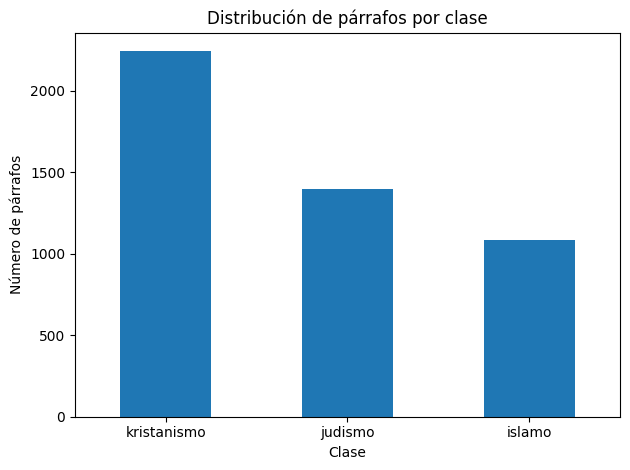

In [4]:

import matplotlib.pyplot as plt

# Número de párrafos por clase
conteo_clases = df["class"].value_counts()

print("Número de párrafos por clase:")
display(conteo_clases.to_frame(name="Número de párrafos"))

# Gráfico de distribución
conteo_clases.plot(kind="bar", rot=0)
plt.title("Distribución de párrafos por clase")
plt.xlabel("Clase")
plt.ylabel("Número de párrafos")
plt.tight_layout()
plt.show()


Estadísticas de longitud de los párrafos:


,longitud
count,4725.000000
mean,59.081905
std,41.132948
min,15.000000
25%,29.000000
50%,48.000000
75%,76.000000
max,364.000000


Longitud media por clase:


,Longitud media
class,
islamo,66.349309
judismo,56.265569
kristanismo,57.320553


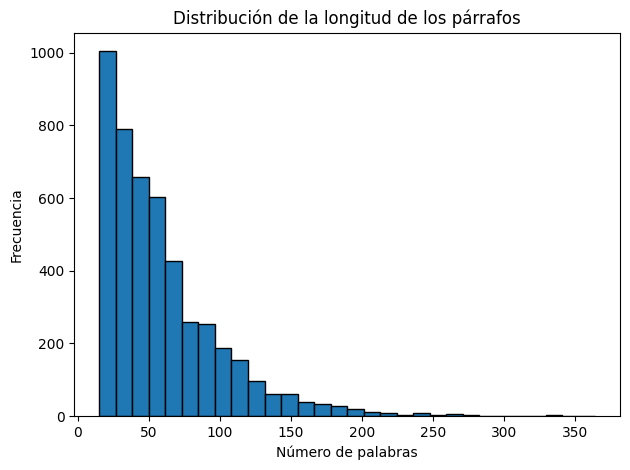

In [5]:

# Calcular la longitud de cada párrafo en palabras
df["longitud"] = df["text"].astype(str).apply(lambda texto: len(texto.split()))

# Estadísticas generales
print("Estadísticas de longitud de los párrafos:")
display(df["longitud"].describe().to_frame())

# Longitud media por clase
print("Longitud media por clase:")
display(df.groupby("class")["longitud"].mean().to_frame("Longitud media"))

# Distribución de las longitudes
df["longitud"].plot(kind="hist", bins=30, edgecolor="black")
plt.title("Distribución de la longitud de los párrafos")
plt.xlabel("Número de palabras")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()


## 3. Preprocesado con nuestra librería

Usamos `esperanto_nlp` para tokenizar y lematizar. Nos quedamos con los **lemas en minúsculas** de las palabras alfabéticas (`is_alpha`) que **no** son stop-words (`is_stop`). Así `judoj`, `judon` y `judo` acaban siendo el mismo término, y se eliminan puntuación, números y palabras funcionales (`la`, `kaj`, `en`...).

In [ ]:
import random
import numpy as np

# Semillas fijas para que los resultados sean reproducibles
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Las clases salen del dataset (nada escrito a mano), así que el cuaderno
# funciona con el dataset de otro equipo cambiando solo DATASET_URL
CLASSES = sorted(df["class"].unique())
print("Clases:", CLASSES)


def preprocess(text):
    """Lemas en minúsculas de las palabras alfabéticas que no son stop-words."""
    return [t.lemma_.lower() for t in nlp(text) if t.is_alpha and not t.is_stop]


# Ejemplo antes / después
ejemplo = df["text"].iloc[0]
lemas = preprocess(ejemplo)
print("Texto original   :", ejemplo[:200], "...")
print("Tras preprocesar :", lemas[:15], "...")
print(f"Tokens: {len(ejemplo.split())} palabras -> {len(lemas)} lemas útiles")

## 4. Representación TF-IDF

`TfidfVectorizer` acepta un `analyzer` propio: le pasamos `preprocess`, de modo que el vocabulario se construye con los lemas de **nuestra** librería y no con el tokenizador por defecto de scikit-learn. TF-IDF da más peso a los términos frecuentes en un párrafo pero poco comunes en el resto del corpus.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer


def make_tfidf():
    return TfidfVectorizer(analyzer=preprocess)


# Demostración sobre una muestra pequeña
demo = make_tfidf()
matriz = demo.fit_transform(df["text"].head(200))
print("Matriz TF-IDF (200 párrafos):", matriz.shape,
      "-> documentos x términos del vocabulario")

## 5. Entrenamiento y comparación de modelos

Separamos **train (80 %) y test (20 %)** de forma estratificada y con `random_state=42`, para mantener la proporción de clases y poder reproducir el resultado. Cada modelo es un `Pipeline` (TF-IDF + clasificador), de modo que el TF-IDF se ajusta **solo con el train** y no hay fuga de información hacia el test.

Comparamos:
- **Naive Bayes multinomial**: línea base clásica para texto.
- **Complement Naive Bayes**: variante de Naive Bayes pensada para clases desequilibradas.
- **Regresión logística** con `class_weight="balanced"`: pondera más las clases minoritarias por el desequilibrio (kristanismo tiene el doble de párrafos que islamo).

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.pipeline import Pipeline

X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["class"],
    test_size=0.2, stratify=df["class"], random_state=SEED,
)
print("Train:", len(X_train), "| Test:", len(X_test))

modelos = {
    "Naive Bayes": Pipeline([("tfidf", make_tfidf()), ("clf", MultinomialNB())]),
    "Complement NB": Pipeline([("tfidf", make_tfidf()), ("clf", ComplementNB())]),
    "Regresión logística": Pipeline([
        ("tfidf", make_tfidf()),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000,
                                   random_state=SEED)),
    ]),
}

predicciones, filas = {}, []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    predicciones[nombre] = pred
    filas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "F1 macro": f1_score(y_test, pred, average="macro"),
    })

comparativa = pd.DataFrame(filas).set_index("Modelo").round(3)
display(comparativa)

## 6. Evaluación

Como las clases están desequilibradas, la métrica de referencia es el **F1 macro** (promedia el F1 de cada clase sin dar más peso a la mayoritaria); la *accuracy* por sí sola podría ocultar que se ignoran las clases pequeñas.

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

mejor = comparativa["F1 macro"].idxmax()
print("Mejor modelo según F1 macro:", mejor)
print()
print(classification_report(y_test, predicciones[mejor], digits=3))

# Matriz de confusión: línea base (Naive Bayes) frente al mejor modelo
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
for eje, nombre in zip(ejes, ["Naive Bayes", mejor]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicciones[nombre], labels=CLASSES,
        cmap="Blues", ax=eje, colorbar=False,
    )
    eje.set_title(nombre)
plt.tight_layout()
plt.show()